# Locating the DBTT with active learning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/digiLab-ai/dbtt-active-learning/blob/main/DBTT_active_learning.ipynb)

A Charpy impact campaign exists to answer one question: **where is the
ductile–brittle transition temperature, and how sure are we?** Specimens are
expensive, so the campaign should spend them where they tell us most.

This notebook does the whole thing end to end, against a live
[Uncertainty Engine](https://uncertaintyengine.ai) project:

| Section | What it does |
| --- | --- |
| [1. A simulated test campaign](#scrollTo=section-1) | A Charpy simulator stands in for the test house, so every estimate can be scored against a known truth |
| [2. Active learning on the Engine](#scrollTo=section-2) | Five workflows — train, recommend, visualise, predict, validate — saved to the project and driven in a loop |
| [3. The DBTT, with its uncertainty](#scrollTo=section-3) | The transition read off the trained model, with the uncertainty that comes with it |
| [4. Was the active learning worth it?](#scrollTo=section-4) | Three fixed designs through the same machinery, for comparison |

Energy absorbed is modelled as an asymmetric hyperbolic tangent (AHT):

$$Y(T) = \frac{LS + US}{2} + \frac{US - LS}{2}\,\tanh\!\left(\frac{T - \mathrm{DBTT}}{C(T)}\right)$$

with $C(T) = C_\mathrm{lower}$ below the DBTT and $C_\mathrm{upper}$ above it, and
heteroscedastic measurement noise $\sigma(T) = \sigma_\mathrm{base} + \sigma_\mathrm{rel}\,Y(T)$.

> **Everything you might want to change is in [Settings](#scrollTo=settings),**
> the first cell below — the material, the noise, the initial design, the
> kernel, the acquisition and the plot colours. Nothing further down needs
> editing to re-run on a different material or a different campaign.

> **The code lives in collapsed cells.** Each one is titled with what it
> covers; click the title to unfold it. Nothing is imported from this
> repository, so the notebook runs anywhere its dependencies do.

---
## Setup

The only thing not already on a Colab runtime is the Uncertainty Engine SDK.
`uncertainty-engine` on PyPI is the **remote API client**; an unpublished
distribution of the same name provides an in-process modelling library and
shadows it, so if imports start failing in confusing ways, check which one the
environment has.

In [1]:
import importlib
import importlib.metadata as metadata
import importlib.util
import subprocess
import sys

#: (import name, distribution name, pip specifier). The import name is what
#: this notebook uses; the distribution name is what carries the version, and
#: the two differ often enough to be worth keeping apart.
REQUIREMENTS = [
    ("uncertainty_engine", "uncertainty-engine", "uncertainty-engine>=0.15,<0.16"),
    ("dotenv", "python-dotenv", "python-dotenv>=1.0"),
    ("pydantic", "pydantic", "pydantic>=2.6"),
    # Needed to compare the versions above against their specifiers. Without
    # it the check below degrades to "is it present at all", which is how an
    # SDK too old to work got through on a local kernel once already.
    ("packaging", "packaging", "packaging>=23.0"),
]


def _version(distribution: str):
    """The installed version of a distribution, or None if it is absent."""
    try:
        return metadata.version(distribution)
    except metadata.PackageNotFoundError:
        return None


def _satisfied(module: str, distribution: str, spec: str) -> bool:
    """Whether the right distribution is present at an acceptable version."""
    have = _version(distribution)
    if have is None or importlib.util.find_spec(module) is None:
        return False
    try:
        from packaging.requirements import Requirement
    except ImportError:
        return True  # cannot check the range here; presence will have to do
    return Requirement(spec).specifier.contains(have, prereleases=True)


missing = [spec for module, dist, spec in REQUIREMENTS
           if not _satisfied(module, dist, spec)]

if missing:
    # Deliberately not the %pip magic. It hands its line to a shell, and the
    # shell reads the < and > of a version specifier as redirections: it
    # writes a file called "=0.15," and then fails on a missing "=0.16"
    # without pip ever running - and without raising, so the notebook carries
    # on to the imports and dies there, pointing at the wrong cell. An argv
    # list has no shell in it to misread.
    print("installing:", ", ".join(missing))
    done = subprocess.run(
        [sys.executable, "-m", "pip", "install", "--quiet", *missing],
        capture_output=True, text=True,
    )
    if done.returncode != 0:
        raise RuntimeError("pip could not install the dependencies:\n\n"
                           + (done.stderr or done.stdout).strip())
    importlib.invalidate_caches()

# Say plainly what is wrong, here, rather than failing in a later cell with a
# traceback that points at the import instead of at the environment.
for module, dist, spec in REQUIREMENTS:
    if _satisfied(module, dist, spec):
        print(f"  {dist} {_version(dist)}")
        continue

    found = importlib.util.find_spec(module)
    detail = [f"{dist} is installed at {_version(dist)}, which does not satisfy {spec!r}."]
    if found is not None and found.origin:
        detail.append(f"  the import `{module}` resolves to: {found.origin}")
        detail.append("  If another distribution provides that same import name - the "
                      "in-process modelling library shares it with the SDK - then no "
                      "amount of installing will help, and the fix is to change "
                      "environment or kernel.")
    if module in sys.modules:
        detail.append(f"  `{module}` is already imported in this session, so an "
                      "upgrade will not take effect until the runtime is restarted.")
    raise RuntimeError("\n".join(detail))

  uncertainty-engine 0.15.0
  python-dotenv 1.2.3
  pydantic 2.13.5
  packaging 26.3


In [2]:
import io
import os
import tempfile
from dataclasses import dataclass, field
from pathlib import Path
from typing import Any, Dict, List, Optional, Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pydantic import BaseModel, ConfigDict, Field, model_validator

from importlib.metadata import version

print(f"uncertainty-engine SDK {version('uncertainty-engine')}")

uncertainty-engine SDK 0.15.0


---
<a id="settings"></a>
## Settings

Everything meant to be changed lives in the next cell. Nothing below it needs
editing to re-run this notebook on a different material, a different campaign
or a different model.

The first two groups describe the **specimen the simulator breaks** — in a real
campaign they are the unknown the testing exists to find, and here they are
the ground truth every estimate is scored against. The rest configure the
campaign, the Engine model, and the figures.

In [3]:
# ====================== THE MATERIAL (ground truth) ======================
# A real campaign does not know these. The simulator does, so the notebook
# can score itself. Y(T) = (LS+US)/2 + (US-LS)/2 * tanh((T - DBTT) / C(T))
TRUE_DBTT        = -40.0    # C   the transition temperature to be found
TRUE_LOWER_SHELF =   5.0    # J   brittle plateau, LS
TRUE_UPPER_SHELF = 200.0    # J   ductile plateau, US
TRUE_WIDTH_LOWER =  30.0    # C   transition width C below the DBTT
TRUE_WIDTH_UPPER =  30.0    # C   ... and above it; equal values = symmetric

# ===================== MEASUREMENT NOISE =================================
# sigma(T) = NOISE_BASE + NOISE_RELATIVE * Y(T): Charpy scatter grows with
# absorbed energy, so the ductile shelf is noisier than the brittle one.
NOISE_BASE     = 3.0        # J   scatter floor, present even on the lower shelf
NOISE_RELATIVE = 0.10       # -   added scatter as a fraction of energy absorbed
SIMULATOR_SEED = 0          # reproducible specimens; None for a fresh campaign

# ===================== THE CAMPAIGN ======================================
BOUNDS               = (-120.0, 100.0)              # testable range [C]
SEED_TEMPERATURES    = [-120.0, 100.0] # the initial design
ITERATIONS           = 6                            # active-learning iterations
POINTS_PER_ITERATION = 1                            # specimens chosen per iteration

# ===================== THE MODEL =========================================
# Straight through to the Engine's ModelConfig and Recommend nodes.
KERNEL      = "LIN+RBF"            # LIN M12 M32 M52 PER RBF RQF, composed
                                   # with + (additive) and * (multiplicative),
                                   # e.g. "(M52*PER)+RQF". LIN+RBF is a linear
                                   # trend plus smooth local structure; the
                                   # LIN term is what keeps the fit from
                                   # wandering past the end specimens.
MODEL_TYPE  = "SingleTaskGPTorch"  # or SingleTaskVariationalGPTorch
WARP_INPUTS = False                # learn a transformation of the input space;
                                   # worth trying where the curve varies at
                                   # different rates across the range
MODEL_SEED  = 0

ACQUISITION = "qNIPV"              # see ACQUISITIONS in section 2 for the rest

# The GP's MEAN FUNCTION is deliberately absent from this list: the Engine
# does not expose it. `ModelConfig` takes a kernel, not a mean, and
# `TrainModel` takes only (config, inputs, outputs). The kernel is the lever
# you have — the LIN term in the default "LIN+RBF" is what lets the fit carry
# a linear trend, which is most of what a non-constant mean would buy you here.

# ===================== PLOT COLOURS ======================================
COLOURS = {
    "truth":      "0.4",   # the true transition curve
    "gp":         "C0",    # GP mean and band, in the per-iteration panels
    "posterior":  "C3",    # the final GP posterior, section 3
    "tests":      "C1",    # specimens measured
    "picked":     "C3",    # where the acquisition chose to test next
    "dbtt":       "C3",    # the DBTT estimated from the model
    "true_dbtt":  "C2",    # the DBTT the simulator actually used
}

### Credentials

Three values are needed to reach the Engine:

| Key | What it is |
| --- | --- |
| `UE_USERNAME` | your Uncertainty Engine login |
| `UE_PASSWORD` | your password |
| `UE_PROJECT_NAME` | the project to work in. It **must already exist** — projects can be viewed and added to here: [https://uncertaintyengine.ai/projects](https://uncertaintyengine.ai/projects) |

**In VS Code, or any local Jupyter.** Put them in a file called `.env`, beside
this notebook:

```
UE_USERNAME=you@example.com
UE_PASSWORD=your-password
UE_PROJECT_NAME=Test
```

`.env` is listed in `.gitignore` and must never be committed. Copy
`.env.example` rather than editing it, so the template stays in the repository
with its keys blank. In VS Code, pick the kernel from the virtualenv you
installed into — the top-right kernel picker — and `python-dotenv` will read
the file from the notebook's working directory.

**In Google Colab.** Do not upload a `.env`: a runtime's filesystem outlives
the cell that wrote it and is easy to leak into a saved notebook. Use the
Secrets panel instead — the **🔑 key icon** in the left sidebar — adding one
secret per key above and switching **Notebook access** on for each. The Colab
badge at the top of this notebook opens it straight from GitHub, and the
repository is public, so no GitHub authorisation is needed.

`load_credentials()` tries Colab secrets first, then `.env`, then whatever is
already in the environment. It returns only *where* the credentials came from,
never what they are, so this cell's output is safe to commit.

In [4]:
#@title Credentials and connection { display-mode: "form" }
# Covers
#   load_credentials()   Colab secrets first, then `.env`, then the environment.
#                        Returns only *where* they came from, never the values.
#   project_name()       the Engine project to work in, from $UE_PROJECT_NAME.
#   connect()            authenticate and resolve (client, project_id).
#
# Projects are created in the Uncertainty Engine GUI, not from the SDK, so the
# project named here must already exist.

CREDENTIAL_KEYS = ("UE_USERNAME", "UE_PASSWORD")
PROJECT_KEY = "UE_PROJECT_NAME"


def load_credentials(env_path: str = ".env") -> str:
    """Load Engine credentials into the process environment.

    Returns ``"colab"``, ``"dotenv"``, ``"environment"`` or ``"missing"``. The
    values themselves are never returned or logged, so the output of this cell
    is safe to commit with the notebook.
    """
    keys = CREDENTIAL_KEYS + (PROJECT_KEY,)

    try:  # Google Colab secrets (the key icon in the left sidebar)
        from google.colab import userdata  # type: ignore

        found = False
        for key in keys:
            try:
                os.environ[key] = userdata.get(key)
                found = True
            except Exception:
                pass
        if found:
            return "colab"
    except ImportError:
        pass

    path = Path(env_path)
    if path.exists():
        from dotenv import load_dotenv

        load_dotenv(path)
        return "dotenv"

    if all(os.environ.get(key) for key in CREDENTIAL_KEYS):
        return "environment"
    return "missing"


def credentials_present() -> bool:
    """Whether every credential key is set. Does not read the values."""
    return all(os.environ.get(key) for key in CREDENTIAL_KEYS)


def project_name(override: Optional[str] = None) -> str:
    """The Engine project to work in: ``override``, else ``$UE_PROJECT_NAME``."""
    name = override or os.environ.get(PROJECT_KEY)
    if not name:
        raise RuntimeError(
            f"No Engine project named. Set {PROJECT_KEY} in your .env (or in "
            "Colab secrets), or pass project_name=... explicitly. Projects are "
            "created in the Uncertainty Engine GUI, not from the SDK."
        )
    return name


def connect(name: Optional[str] = None):
    """Authenticate and resolve a project id. Returns ``(client, project_id)``."""
    from uncertainty_engine import Client

    if not credentials_present():
        raise RuntimeError(
            "Uncertainty Engine credentials are not set. Put "
            f"{' and '.join(CREDENTIAL_KEYS)} in a .env file beside this "
            "notebook, or in Colab secrets, then re-run load_credentials()."
        )

    client = Client()
    client.authenticate()
    return client, client.projects.get_project_id_by_name(project_name(name))

In [5]:
source = load_credentials()
print(f"credentials from: {source}")

client, project_id = connect()
print(f"project {project_name()!r} -> {project_id}")

credentials from: dotenv


project 'Test' -> 6ae27221bac4a9e13468f79d


---
<a id="section-1"></a>
## 1. A simulated test campaign

The simulator stands in for the test house. It follows the uncertainty-engine
`Simulator` contract — config-driven construction, a leaf `_forward(X)` holding
the raw $X \to y$ map, and the public verb `simulate(X)` returning a
`SimulationResult` — so code written against it ports to the real thing with a
change of import.

Because it is a simulator it knows the answer, and that is the point: every
estimate later in the notebook can be scored against a DBTT we actually know.

In [6]:
#@title The Charpy simulator { display-mode: "form" }
# Covers
#   AHTParams / NoiseParams / SpecimenParams / CharpySimulatorConfig
#                        validated pydantic config; a whole campaign is
#                        reproducible from these fields alone.
#   SimulationResult     what `simulate` returns: `y` plus auxiliary payload.
#   Simulator            the uncertainty-engine `Simulator` noun, in miniature:
#                        config-driven construction, a leaf `_forward(X)`
#                        implementing the raw X -> y map, and the public verb
#                        `simulate(X)`. Code written against it ports to the
#                        engine with a change of import.
#   CharpySimulator      test temperature [C] -> energy absorbed [J], as an
#                        asymmetric hyperbolic tangent plus heteroscedastic
#                        noise. `run()` returns test-house-shaped rows.
#   plot_dataset         scatter of energy absorbed against test temperature.
#
# The forward map is *stochastic*: one `simulate` call is one broken specimen,
# a single realisation rather than a summary of the output law.

#: Column headers of the test-result table, matching the test-house spreadsheet.
COLUMNS = [
    "Material", "Condition", "Processing", "Orientation",
    "NEURONE specimen ID", "Test house specimen ID", "Specimen Design",
    "Specimen location", "Specimen Type", "Notch type",
    "Test temperature (C)", "Energy absorbed (J)",
]

TEMPERATURE_COL = "Test temperature (C)"
ENERGY_COL = "Energy absorbed (J)"


class SimulationResult(BaseModel):
    """`y` is the canonical output of the forward map; `outputs` is everything else."""

    model_config = ConfigDict(arbitrary_types_allowed=True)

    y: Any = Field(None, description="Canonical output(s) of the forward map X -> y.")
    outputs: Dict[str, Any] = Field(
        default_factory=dict,
        description="Auxiliary payload: diagnostics, provenance, units, ground truth.",
    )


class AHTParams(BaseModel):
    """Asymmetric hyperbolic tangent (AHT) transition curve.

        Y(T) = (LS + US) / 2 + (US - LS) / 2 * tanh((T - DBTT) / C(T))

    with ``C(T) = width_lower`` below the DBTT and ``width_upper`` above it.
    Setting the two widths equal recovers the symmetric hyperbolic tangent.
    """

    model_config = ConfigDict(extra="forbid")

    lower_shelf: float = Field(5.0, ge=0.0, description="Lower (brittle) shelf energy, LS [J].")
    upper_shelf: float = Field(200.0, gt=0.0, description="Upper (ductile) shelf energy, US [J].")
    dbtt: float = Field(-40.0, description="Ductile-brittle transition temperature [C].")
    width_lower: float = Field(30.0, gt=0.0, description="Transition width C below the DBTT [C].")
    width_upper: float = Field(30.0, gt=0.0, description="Transition width C above the DBTT [C].")

    @model_validator(mode="after")
    def _check_shelves(self) -> "AHTParams":
        if self.upper_shelf <= self.lower_shelf:
            raise ValueError("upper_shelf must be greater than lower_shelf")
        return self


class NoiseParams(BaseModel):
    """Heteroscedastic measurement noise, ``sigma(T) = base + relative * Y(T)``."""

    model_config = ConfigDict(extra="forbid")

    base: float = Field(3.0, ge=0.0, description="Constant noise standard deviation [J].")
    relative: float = Field(0.10, ge=0.0, description="Noise std as a fraction of true energy [-].")
    energy_floor: float = Field(
        0.0, ge=0.0,
        description="Sampled energies clipped here [J]; a Charpy test cannot absorb negative energy.",
    )


class SpecimenParams(BaseModel):
    """Specimen provenance carried through to the test-result table."""

    model_config = ConfigDict(extra="forbid")

    material: str = Field("EUROFER EAF", description="Material designation.")
    condition: str = Field("Base", description="Material condition.")
    processing: str = Field("Rolled", description="Processing route.")
    orientation: str = Field("RD", description="Specimen orientation.")
    specimen_design: str = Field("ASTM", description="Specimen design standard.")
    specimen_location: str = Field("EAF 1a Plate 1", description="Where the specimen came from.")
    specimen_type: str = Field("Charpy", description="Test specimen type.")
    notch_type: str = Field("V notch", description="Notch geometry.")
    neurone_id_prefix: str = Field("NRN2025-", description="Prefix for generated NEURONE IDs.")
    neurone_id_digits: int = Field(4, ge=1, description="Zero-padded width of the NEURONE ID.")


class CharpySimulatorConfig(BaseModel):
    """Everything `CharpySimulator` needs, as validated fields."""

    model_config = ConfigDict(extra="forbid")

    name: str = Field("eurofer_eaf", description="Short name for this campaign.")
    description: Optional[str] = Field(None, description="Free-text note.")
    curve: AHTParams = Field(default_factory=AHTParams)
    noise: NoiseParams = Field(default_factory=NoiseParams)
    specimen: SpecimenParams = Field(default_factory=SpecimenParams)
    seed: Optional[int] = Field(0, description="Random seed. None gives non-reproducible draws.")
    temperature_range: tuple = Field(
        (-150.0, 100.0),
        description="Physically sensible test-temperature bounds [C]; requests outside are rejected.",
    )

    @model_validator(mode="after")
    def _check_range(self) -> "CharpySimulatorConfig":
        lo, hi = self.temperature_range
        if hi <= lo:
            raise ValueError("temperature_range must be (low, high) with high > low")
        return self


class Simulator:
    """Abstract base for all simulators: the ``X -> y`` forward map.

    Construction is config-driven; ``X`` is an argument to ``simulate``, never
    stored on the config.
    """

    def __init__(self, config) -> None:
        self.config = config

    def _forward(self, X):
        """Evaluate the raw forward map ``X -> y``. Leaves implement this."""
        raise NotImplementedError

    def simulate(self, X) -> SimulationResult:
        """One evaluation of the forward map, wrapped in a result."""
        return self.build_result(X, self._forward(X))

    def build_result(self, X, y) -> SimulationResult:
        """The extension point every ``simulate`` goes through."""
        return SimulationResult(y=y)

    @classmethod
    def describe(cls) -> Dict[str, Any]:
        """Introspect the leaf without instantiating it."""
        return {
            "name": cls.__name__,
            "summary": (cls.__doc__ or "").strip().split("\n")[0],
        }


class CharpySimulator(Simulator):
    """Charpy impact test: test temperature [C] -> energy absorbed [J].

    Repeated calls at the same temperature give different energies, as in a
    real campaign.
    """

    def __init__(self, config: Optional[CharpySimulatorConfig] = None) -> None:
        super().__init__(config or CharpySimulatorConfig())
        self._rng = np.random.default_rng(self.config.seed)

    # ----- the forward map -----
    def _forward(self, X) -> np.ndarray:
        """Draw noisy energy-absorbed measurements [J]. Advances the random state."""
        t = np.atleast_1d(np.asarray(X, dtype=float))
        self._validate_temperatures(t)
        draw = self._rng.normal(loc=self.true_curve(t), scale=self.noise_std(t))
        return np.clip(draw, self.config.noise.energy_floor, None)

    def build_result(self, X, y) -> SimulationResult:
        """Wrap the measurement, carrying the ground truth as auxiliary payload.

        ``outputs["true_energy"]`` and ``outputs["noise_std"]`` have **no
        counterpart in a real experiment**. They are here to score how well the
        active learning recovers the truth, and must never be fed to the GP.
        """
        t = np.atleast_1d(np.asarray(X, dtype=float))
        return SimulationResult(
            y=y,
            outputs={
                "temperature": t,
                "true_energy": self.true_curve(t),
                "noise_std": self.noise_std(t),
                "dbtt": self.dbtt,
                "units": {"temperature": "C", "energy": "J"},
            },
        )

    # ----- ground truth (simulator-only) -----
    def true_curve(self, temperature) -> np.ndarray:
        """Noise-free energy absorbed [J] at the given temperature(s) [C]."""
        curve = self.config.curve
        t = np.asarray(temperature, dtype=float)
        width = np.where(t < curve.dbtt, curve.width_lower, curve.width_upper)
        midpoint = 0.5 * (curve.lower_shelf + curve.upper_shelf)
        amplitude = 0.5 * (curve.upper_shelf - curve.lower_shelf)
        return midpoint + amplitude * np.tanh((t - curve.dbtt) / width)

    def noise_std(self, temperature) -> np.ndarray:
        """Measurement standard deviation [J] at the given temperature(s) [C]."""
        noise = self.config.noise
        return noise.base + noise.relative * self.true_curve(temperature)

    @property
    def dbtt(self) -> float:
        """The ground-truth DBTT [C] the active-learning loop is chasing."""
        return self.config.curve.dbtt

    # ----- test-campaign convenience -----
    def run(self, temperatures, start_index: int = 1) -> pd.DataFrame:
        """Test specimens at ``temperatures`` and return a test-result table.

        The table carries only what a real test house would report: the
        noise-free truth stays on the `SimulationResult` and never reaches the
        dataset. ``start_index`` continues the specimen numbering.
        """
        result = self.simulate(temperatures)
        t = result.outputs["temperature"]
        spec = self.config.specimen
        numbers = np.arange(start_index, start_index + t.size)

        return pd.DataFrame(
            {
                "Material": spec.material,
                "Condition": spec.condition,
                "Processing": spec.processing,
                "Orientation": spec.orientation,
                "NEURONE specimen ID": [
                    f"{spec.neurone_id_prefix}{n:0{spec.neurone_id_digits}d}" for n in numbers
                ],
                "Test house specimen ID": numbers,
                "Specimen Design": spec.specimen_design,
                "Specimen location": spec.specimen_location,
                "Specimen Type": spec.specimen_type,
                "Notch type": spec.notch_type,
                TEMPERATURE_COL: t,
                ENERGY_COL: np.round(result.y, 2),
            },
            columns=COLUMNS,
        )

    def _validate_temperatures(self, t: np.ndarray) -> None:
        lo, hi = self.config.temperature_range
        if np.any(t < lo) or np.any(t > hi):
            bad = t[(t < lo) | (t > hi)]
            raise ValueError(
                f"Test temperature(s) {bad.tolist()} outside the configured range [{lo}, {hi}] C."
            )


def plot_dataset(data: pd.DataFrame, ax=None, label: str = "Measurements", **scatter_kwargs):
    """Scatter energy absorbed against test temperature."""
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 4.5))

    style = {"s": 45, "color": "k", "zorder": 3}
    style.update(scatter_kwargs)
    ax.scatter(data[TEMPERATURE_COL], data[ENERGY_COL], label=label, **style)

    ax.set_xlabel("Test temperature [C]")
    ax.set_ylabel("Energy absorbed [J]")
    ax.set_title("Charpy impact energy vs temperature")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", fontsize=9)
    return ax

In [7]:
simulator = CharpySimulator(
    CharpySimulatorConfig(
        curve=AHTParams(
            dbtt=TRUE_DBTT,
            lower_shelf=TRUE_LOWER_SHELF, upper_shelf=TRUE_UPPER_SHELF,
            width_lower=TRUE_WIDTH_LOWER, width_upper=TRUE_WIDTH_UPPER,
        ),
        noise=NoiseParams(base=NOISE_BASE, relative=NOISE_RELATIVE),
        seed=SIMULATOR_SEED,
    )
)

print(CharpySimulator.describe())
print(f"\ntrue DBTT: {simulator.dbtt} C")
simulator.config.curve

{'name': 'CharpySimulator', 'summary': 'Charpy impact test: test temperature [C] -> energy absorbed [J].'}

true DBTT: -40.0 C


AHTParams(lower_shelf=5.0, upper_shelf=200.0, dbtt=-40.0, width_lower=30.0, width_upper=30.0)

### One measurement

`simulate(X)` runs the forward map **once**. The map is stochastic, so one call
is one broken specimen — a single realisation, not a summary of the output law.

In [8]:
result = simulator.simulate(-45.0)

print(f"Measured:         {result.y[0]:7.2f} J")
print(f"True (noiseless): {result.outputs['true_energy'][0]:7.2f} J")
print(f"Noise sigma:      {result.outputs['noise_std'][0]:7.2f} J")

Measured:           87.86 J
True (noiseless):   86.40 J
Noise sigma:        11.64 J


`result.outputs` carries the simulator's ground truth alongside the
measurement. This has **no counterpart in a real experiment** — it is here to
score the active learning, and must never reach the GP. Call it again at the
same temperature and you get a different specimen:

In [9]:
repeats = [simulator.simulate(-45.0).y[0] for _ in range(5)]
print("Five specimens at -45 C:", [f"{e:.1f}" for e in repeats])

Five specimens at -45 C: ['84.9', '93.9', '87.6', '80.2', '90.6']


### The initial design

Two specimens, one at each end of the testable range. They pin the shelves
that the transition sits between; without them the curve is unidentifiable, and
the acquisition has nothing to reduce uncertainty *against*. Everything after
this is chosen by the Engine.

This is the leanest design that still identifies the curve, and it leaves the
shelves resting on a single specimen each. Section 3 reads the shelves off the
fitted slice, so a shelf the GP overshoots moves the mid-shelf energy and the
DBTT with it — adding a second specimen at each end is the first thing to try
if the interval comes back wide.

In [10]:
campaign = simulator.run(SEED_TEMPERATURES, start_index=1)
campaign[["NEURONE specimen ID", TEMPERATURE_COL, ENERGY_COL]]

,NEURONE specimen ID,Test temperature (C),Energy absorbed (J)
0,NRN2025-0001,-120.0,10.62
1,NRN2025-0002,100.0,221.76


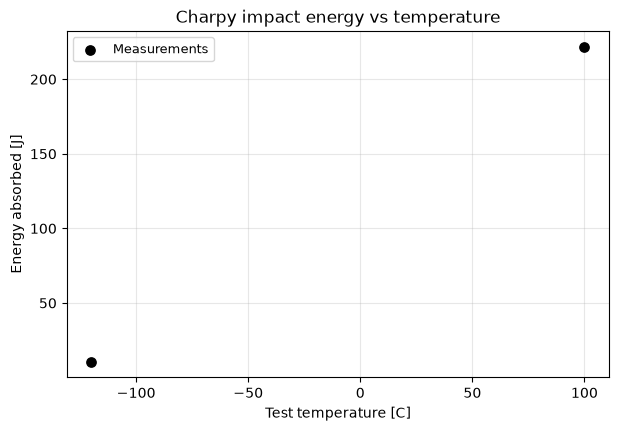

In [11]:
plot_dataset(campaign)
plt.show()

---
<a id="section-2"></a>
## 2. Active learning on the Engine

Everything that models — the GP, the acquisition, the scoring — runs on the
**remote Uncertainty Engine**, not in this process. The cell below assembles
five workflow graphs and saves them to the project, after which they are
visible in the Engine GUI and can be inspected, re-run and edited there. That
is the point of building them programmatically rather than only executing them.

| Workflow | Nodes | Purpose |
| --- | --- | --- |
| **Train model** | `LoadDataset` → `FilterDataset` ×2 → `ModelConfig` → `TrainModel` → `Save` | Fit a GP to the campaign so far |
| **Active Learning** | `LoadModel` → `Recommend` → `Save` | Where to test next |
| **GP plot** | `LoadModel` + `CreateDatasetSlice` → `PredictModel` → `UncertaintyPlot` | The posterior, returned inline with the job |
| **Predict slice** | `LoadModel` + `CreateDatasetSlice` → `PredictModel` → `Save` ×2 | The same posterior, **saved** as project datasets |
| **Validate** | `LoadModel` + `LoadDataset` → `FilterDataset` ×2 → `PredictModel` → `ScoreModel` + `ParityPlot` | Scores and a parity plot |

The campaign is uploaded as **one** dataset and `FilterDataset` splits out the
input and output columns, so each iteration re-uploads a single CSV.

In [12]:
#@title Engine workflow builders { display-mode: "form" }
# Covers, in three groups.
#
# Datasets
#   resource_id()        a project resource's id by name, or None.
#   upload_dataset()     write a frame to the project; *create* on the first
#                        call, *new version of the same id* after that. The
#                        saved workflows point at that id, so it must not move.
#   download_dataset()   a dataset resource back as a frame.
#
# Graph builders — the five workflows, matching the ones exported from the GUI
#   build_training_workflow()        LoadDataset -> FilterDataset x2 ->
#                                    ModelConfig -> TrainModel -> Save
#   build_recommendation_workflow()  LoadModel -> Recommend -> Save
#   build_gp_plot_workflow()         LoadModel + CreateDatasetSlice ->
#                                    PredictModel -> UncertaintyPlot
#   build_prediction_workflow()      the same posterior, but *saved* as two
#                                    project datasets rather than a plot payload
#   build_validation_workflow()      ... -> ScoreModel + ParityPlot
#
# Running and reading
#   save_workflow()      put a graph in the project workspace, by name. It then
#                        shows up in the GUI and can be re-run and edited there.
#   run_saved()          run one by id, optionally overriding node inputs.
#   outputs()            unwrap `JobInfo.outputs`, which nests the map one deep.
#   uncertainty_curve()  the posterior a GP-plot job returns inline.
#   saved_prediction()   the posterior a prediction job saved, downloaded.
#   recommended_points() the points a recommendation job chose.
#
# Node schemas are resolved from the Node Registry at run time (SDK >= 0.15),
# so these follow whatever version the Engine currently serves.

#: Our acquisition names mapped onto the SDK's `AvailableAcquisitions`.
ACQUISITIONS: Dict[str, str] = {
    # Uncertainty reduction - what a characterisation campaign wants.
    "qNIPV": "MonteCarloNegativeIntegratedPosteriorVariance",
    "PSD": "PosteriorStandardDeviation",
    # Optimisation - these chase the *largest* energy, not the transition,
    # so they are the wrong tool here and are listed for completeness.
    "EI": "ExpectedImprovement",
    "LogEI": "LogExpectedImprovement",
    "qEI": "MonteCarloExpectedImprovement",
    "qLogEI": "MonteCarloLogExpectedImprovement",
    "PM": "PosteriorMean",
}

#: The campaign columns the GP is trained on.
INPUT_COLUMNS: List[str] = [TEMPERATURE_COL]
OUTPUT_COLUMNS: List[str] = [ENERGY_COL]


# ----- datasets -------------------------------------------------------------
def resource_id(client, project_id: str, name: str, resource_type: str = "dataset"):
    """The id of a project resource by name, or ``None`` if there is no such one."""
    records = client.resources.list_resources(project_id, resource_type)
    matches = [r for r in records if getattr(r, "name", None) == name]
    if not matches:
        return None
    if len(matches) > 1:
        raise RuntimeError(
            f"{len(matches)} {resource_type} resources are named {name!r} in this "
            "project; rename or delete the duplicates."
        )
    return matches[0].id


def upload_dataset(client, project_id: str, frame: pd.DataFrame, name: str) -> str:
    """Write a frame to the project workspace and return its resource id.

    Creating and versioning are *different calls*: ``upload`` refuses a name the
    project already holds (409 Conflict), and ``update`` adds a new version to
    an existing resource, keeping its id. The active-learning loop depends on
    that id staying put — the saved workflows point at it — so this picks the
    right call rather than assuming either.
    """
    existing = resource_id(client, project_id, name)
    with tempfile.TemporaryDirectory() as directory:
        path = Path(directory) / f"{name}.csv"
        frame.to_csv(path, index=False)
        if existing is None:
            client.resources.upload(
                project_id=project_id, name=name,
                resource_type="dataset", file_path=str(path),
            )
        else:
            client.resources.update(
                project_id=project_id, resource_type="dataset",
                resource_id=existing, file_path=str(path),
            )

    return existing or client.resources.get_resource_id_by_name(
        resource_type="dataset", project_id=project_id, name=name
    )


def download_dataset(client, project_id: str, resource_id_: str) -> pd.DataFrame:
    """Download a dataset resource and parse it as a frame."""
    content = client.resources.download(
        project_id=project_id, resource_type="dataset", resource_id=resource_id_
    )
    return pd.read_csv(io.BytesIO(content))


# ----- node and graph plumbing ----------------------------------------------
def _node(client, node_name: str, label: str, **inputs):
    """Build a node by name; the schema is resolved from the Node Registry."""
    return client.nodes(node_name, label=label, **inputs)


def _resource(resource_id_: str) -> Dict[str, str]:
    """A resource id in the serialised form the load nodes take."""
    from uncertainty_engine_types import ResourceID

    return ResourceID(id=resource_id_).model_dump()


def _workflow(graph, requested_output: Dict[str, Any], client):
    """Wrap a populated graph as an executable workflow."""
    from uncertainty_engine.nodes.workflow import Workflow

    return Workflow(
        graph=graph.nodes,
        inputs=graph.external_input,
        requested_output=requested_output,
        external_input_id=graph.external_input_id,
        client=client,
    )


def _graph():
    """A graph that refuses duplicate labels, since every label here is fixed."""
    from uncertainty_engine.graph import Graph

    return Graph(prevent_node_overwrite=True)


def _output(label: str, handle: str) -> Dict[str, Dict[str, str]]:
    """One entry of a workflow's ``requested_output`` map."""
    return {f"{label}_{handle}": {"node_name": label, "node_handle": handle}}


def _load_dataset(client, project_id: str, resource_id_: str, label: str):
    """A ``LoadDataset`` node. Its output handle is ``file``, not ``dataset``."""
    return _node(client, "LoadDataset", label,
                 project_id=project_id, file_id=_resource(resource_id_))


def _load_model(client, project_id: str, resource_id_: str, label: str):
    """A ``LoadModel`` node. Its output handle is ``file``, not ``model``."""
    return _node(client, "LoadModel", label,
                 project_id=project_id, file_id=_resource(resource_id_))


def _filter(client, source, label: str, columns: Sequence[str]):
    """A ``FilterDataset`` node selecting ``columns`` from a loaded dataset."""
    return _node(client, "FilterDataset", label,
                 dataset=source.make_handle("file"),
                 columns=list(columns), sample_fraction=1)


def _save(client, source, handle: str, project_id: str, file_name: str, label: str):
    """A ``Save`` node. The node input is ``file_id``; it holds the *name*."""
    return _node(client, "Save", label,
                 data=source.make_handle(handle), file_id=file_name,
                 project_id=project_id, account_id=None)


def _slice(client, bounds, num_points: int, variable: Optional[str] = None):
    """A ``CreateDatasetSlice`` node over the model's own input column."""
    return _node(client, "CreateDatasetSlice", "Slice",
                 variable=variable or INPUT_COLUMNS[0],
                 min=str(bounds[0]), max=str(bounds[1]),
                 fixed_values={}, num_points=num_points)


# ----- the five workflows ---------------------------------------------------
def build_training_workflow(
    client, project_id: str, dataset_resource_id: str, model_name: str,
    kernel: str = "LIN+RBF", model_type: str = "SingleTaskGPTorch",
    warp_inputs: bool = False, seed: Optional[int] = 0,
    input_columns: Optional[Sequence[str]] = None,
    output_columns: Optional[Sequence[str]] = None,
):
    """Train a GP on the campaign so far and save the fitted model.

    The campaign is uploaded as *one* dataset; ``FilterDataset`` splits out the
    input and output columns, so the loop re-uploads a single CSV per iteration.
    """
    graph = _graph()

    data = _load_dataset(client, project_id, dataset_resource_id, "Experimental Data")
    temp = _filter(client, data, "Temp", input_columns or INPUT_COLUMNS)
    energy = _filter(client, data, "Energy", output_columns or OUTPUT_COLUMNS)
    config = _node(client, "ModelConfig", "Gaussian Process",
                   model_type=model_type, kernel=kernel,
                   warp_inputs=warp_inputs, seed=seed)
    for node in (data, temp, energy, config):
        graph.add_node(node)

    train = _node(client, "TrainModel", "Train Model",
                  config=config.make_handle("config"),
                  inputs=temp.make_handle("dataset"),
                  outputs=energy.make_handle("dataset"))
    save = _save(client, train, "model", project_id, model_name, "Save")
    graph.add_node(train)
    graph.add_node(save)

    return _workflow(graph, _output("Save", "saved_resource"), client)


def build_recommendation_workflow(
    client, project_id: str, model_resource_id: str, points_name: str,
    acquisition: str = "qNIPV", num_points: int = 1,
):
    """Ask the trained GP for the next test temperature(s)."""
    if acquisition not in ACQUISITIONS:
        raise ValueError(f"acquisition must be one of {sorted(ACQUISITIONS)}, got {acquisition!r}")
    graph = _graph()

    model = _load_model(client, project_id, model_resource_id, "Model")
    graph.add_node(model)

    recommend = _node(client, "Recommend", "Active Learning",
                      model=model.make_handle("file"),
                      number_of_points=str(num_points),
                      acquisition_function=ACQUISITIONS[acquisition])
    save = _save(client, recommend, "recommended_points", project_id, points_name, "Save")
    graph.add_node(recommend)
    graph.add_node(save)

    # `recommended_points` comes back as an S3 reference, not as values, so the
    # saved resource is what the loop actually reads.
    requested = {**_output("Save", "saved_resource"),
                 **_output("Active Learning", "recommended_points")}
    return _workflow(graph, requested, client)


def build_gp_plot_workflow(
    client, project_id: str, model_resource_id: str, bounds,
    num_points: int = 101, variable: Optional[str] = None,
):
    """Predict across the temperature slice — the model visualisation."""
    graph = _graph()

    model = _load_model(client, project_id, model_resource_id, "Model")
    slice_ = _slice(client, bounds, num_points, variable)
    graph.add_node(model)
    graph.add_node(slice_)

    predict = _node(client, "PredictModel", "Predict",
                    model=model.make_handle("file"),
                    dataset=slice_.make_handle("data"))
    plot = _node(client, "UncertaintyPlot", "Uncertainty Plot",
                 X=slice_.make_handle("data"),
                 prediction=predict.make_handle("prediction"),
                 uncertainty=predict.make_handle("uncertainty"))
    graph.add_node(predict)
    graph.add_node(plot)

    # `UncertaintyPlot` returns the whole curve inline — x_vals, mean, std —
    # which is the only posterior that comes back as values. `PredictModel`'s
    # own handles return S3 references, so they are not requested here.
    requested = {**_output("Uncertainty Plot", "data"), **_output("Slice", "data")}
    return _workflow(graph, requested, client)


def build_prediction_workflow(
    client, project_id: str, model_resource_id: str, bounds,
    mean_name: str, uncertainty_name: str,
    num_points: int = 101, variable: Optional[str] = None,
):
    """Predict across a slice and **save** the posterior as project datasets.

    The same shape as `build_gp_plot_workflow`, but where that one returns a
    plot payload that lives only as long as the job, this writes the posterior
    mean and uncertainty to the project, where they persist and can be opened
    in the GUI. They are separate resources because `PredictModel` emits them
    as separate handles and no node here joins two datasets.
    """
    graph = _graph()

    model = _load_model(client, project_id, model_resource_id, "Model")
    slice_ = _slice(client, bounds, num_points, variable)
    graph.add_node(model)
    graph.add_node(slice_)

    predict = _node(client, "PredictModel", "Predict",
                    model=model.make_handle("file"),
                    dataset=slice_.make_handle("data"))
    save_mean = _save(client, predict, "prediction", project_id, mean_name, "Save Mean")
    save_sd = _save(client, predict, "uncertainty", project_id, uncertainty_name, "Save Uncertainty")
    for node in (predict, save_mean, save_sd):
        graph.add_node(node)

    requested = {**_output("Save Mean", "saved_resource"),
                 **_output("Save Uncertainty", "saved_resource"),
                 **_output("Slice", "data")}
    return _workflow(graph, requested, client)


def build_validation_workflow(
    client, project_id: str, model_resource_id: str, dataset_resource_id: str,
    metrics: Sequence[str] = ("MSE", "RMSE", "R2"),
    input_columns: Optional[Sequence[str]] = None,
    output_columns: Optional[Sequence[str]] = None,
):
    """Score the model against a held-out dataset and draw a parity plot."""
    graph = _graph()

    model = _load_model(client, project_id, model_resource_id, "Model")
    data = _load_dataset(client, project_id, dataset_resource_id, "Validation Data")
    temp = _filter(client, data, "Temp", input_columns or INPUT_COLUMNS)
    energy = _filter(client, data, "Energy", output_columns or OUTPUT_COLUMNS)
    for node in (model, data, temp, energy):
        graph.add_node(node)

    predict = _node(client, "PredictModel", "Predict",
                    model=model.make_handle("file"),
                    dataset=temp.make_handle("dataset"))
    score = _node(client, "ScoreModel", "Score",
                  predictions=predict.make_handle("prediction"),
                  truth=energy.make_handle("dataset"),
                  predictions_uncertainty=predict.make_handle("uncertainty"),
                  metrics=list(metrics))
    parity = _node(client, "ParityPlot", "Parity Plot",
                   predictions=predict.make_handle("prediction"),
                   expected=energy.make_handle("dataset"),
                   uncertainties=predict.make_handle("uncertainty"))
    for node in (predict, score, parity):
        graph.add_node(node)

    requested = {**_output("Score", "scores"), **_output("Parity Plot", "plot")}
    return _workflow(graph, requested, client)


# ----- the workspace --------------------------------------------------------
def workflow_id(client, project_id: str, name: str):
    """The id of a saved workflow by name, or ``None`` if there is no such one."""
    records = client.workflows.list_workflows(project_id)
    matches = [r for r in records if getattr(r, "name", None) == name]
    return matches[0].id if matches else None


def save_workflow(client, project_id: str, workflow, name: str) -> str:
    """Save a workflow to the project workspace and return its id.

    Workflow names are unique within a project, so saving over an existing name
    updates that workflow as a new version instead of failing. Re-running this
    notebook therefore revises its workflows rather than duplicating them.
    """
    existing = workflow_id(client, project_id, name)
    if existing is not None:
        return client.workflows.save(project_id=project_id, workflow=workflow, workflow_id=existing)
    return client.workflows.save(project_id=project_id, workflow=workflow, workflow_name=name)


def _completed(response):
    """Return a finished job, or raise with the response body if it failed."""
    if response.status.value != "completed":
        raise RuntimeError(
            f"Workflow did not complete (status {response.status.value}): {response.model_dump()}"
        )
    return response


def run_saved(client, project_id: str, workflow_id_: str, overrides=None):
    """Run a workflow already saved in the project, by id.

    The loop's workhorse: the graphs are built and saved once, then re-run each
    iteration. Nothing needs overriding for that, because every iteration
    re-uploads its dataset under the same resource *name* — a new version of
    the same resource id, which the saved graph already points at.

    ``overrides`` maps ``(node_label, input_handle)`` to a value, for the cases
    where you do want to vary something, such as the acquisition function.
    """
    from uncertainty_engine_types import OverrideWorkflowInput

    inputs = [
        OverrideWorkflowInput(node_label=label, input_handle=handle, value=value)
        for (label, handle), value in (overrides or {}).items()
    ]
    return _completed(
        client.run_workflow(project_id=project_id, workflow_id=workflow_id_, inputs=inputs or None)
    )


# ----- reading results back -------------------------------------------------
def outputs(response) -> Dict[str, Any]:
    """The requested outputs of a finished job, keyed as the builders named them.

    ``JobInfo.outputs`` wraps the map in another ``"outputs"`` key; this unwraps
    it, so callers see the ``"<label>_<handle>"`` keys that were asked for.
    """
    payload = dict(response.outputs or {})
    inner = payload.get("outputs")
    return dict(inner) if isinstance(inner, dict) else payload


def as_frame(payload: Any) -> pd.DataFrame:
    """A node output that carries a CSV payload, as a frame.

    Several nodes (``ScoreModel``, ``CreateDatasetSlice``) return their result
    as ``{"csv": "..."}`` rather than as records.
    """
    if isinstance(payload, dict) and "csv" in payload:
        return pd.read_csv(io.StringIO(payload["csv"]))
    return pd.DataFrame(payload)


def uncertainty_curve(response) -> pd.DataFrame:
    """The posterior from a GP-plot job: grid, mean and standard deviation."""
    data = outputs(response)["Uncertainty Plot_data"]
    label = data.get("x_label", INPUT_COLUMNS[0])
    return pd.DataFrame(
        {label: data["x_vals"], "mean": data["mean"], "sd": data["std"]}
    ).sort_values(label, ignore_index=True)


def saved_prediction(client, project_id: str, response) -> pd.DataFrame:
    """The posterior a prediction job saved, as one frame.

    Downloads the two saved datasets and puts them beside the grid, which came
    back inline with the job. Columns: the input variable, ``mean`` and ``sd``.
    """
    out = outputs(response)
    grid = as_frame(out["Slice_data"])
    mean = download_dataset(client, project_id, out["Save Mean_saved_resource"]["id"])
    sd = download_dataset(client, project_id, out["Save Uncertainty_saved_resource"]["id"])

    frame = pd.DataFrame(
        {
            grid.columns[0]: grid.iloc[:, 0].to_numpy(dtype=float),
            "mean": mean.iloc[:, 0].to_numpy(dtype=float),
            "sd": sd.iloc[:, 0].to_numpy(dtype=float),
        }
    )
    return frame.sort_values(frame.columns[0], ignore_index=True)


def recommended_points(client, project_id: str, response) -> pd.DataFrame:
    """The points a recommendation job chose, downloaded from its saved resource.

    The ``recommended_points`` handle is an S3 reference; the ``Save`` node's
    ``saved_resource`` carries the resource id, which is what can be read back.
    """
    saved = outputs(response)["Save_saved_resource"]
    return download_dataset(client, project_id, saved["id"])

The dataset has to exist before the graphs can point at it, so it is uploaded
first. Training then has to run once, because the other four workflows load a
*model* resource that does not exist until something has saved one.

In [13]:
DATASET_NAME = "dbtt_campaign"
MODEL_NAME = "dbtt_gp"
POINTS_NAME = "dbtt_next_point"
MEAN_NAME = "dbtt_gp_mean"
UNCERTAINTY_NAME = "dbtt_gp_sd"

dataset_id = upload_dataset(client, project_id, campaign, DATASET_NAME)
print(f"dataset resource: {dataset_id}")

dataset resource: 6ae273e3bac4a9e13468f79e


In [14]:
training = build_training_workflow(
    client, project_id, dataset_id, MODEL_NAME,
    kernel=KERNEL, model_type=MODEL_TYPE, warp_inputs=WARP_INPUTS, seed=MODEL_SEED,
)
training_id = save_workflow(client, project_id, training, "Train model")

run_saved(client, project_id, training_id)
model_id = resource_id(client, project_id, MODEL_NAME, "model")
print(f"model resource: {model_id}")

model resource: 6ae273fdbac4a9e13468f7a3


In [15]:
workflows = {
    "Active Learning - Reduce uncertainty": build_recommendation_workflow(
        client, project_id, model_id, POINTS_NAME, acquisition=ACQUISITION, num_points=POINTS_PER_ITERATION
    ),
    "Temp to Energy - GP plot": build_gp_plot_workflow(
        client, project_id, model_id, BOUNDS
    ),
    "Predict slice": build_prediction_workflow(
        client, project_id, model_id, BOUNDS, MEAN_NAME, UNCERTAINTY_NAME
    ),
    "Validate energy model": build_validation_workflow(
        client, project_id, model_id, dataset_id
    ),
}

saved_ids = {
    name: save_workflow(client, project_id, workflow, name)
    for name, workflow in workflows.items()
}
saved_ids["Train model"] = training_id

for name, wid in saved_ids.items():
    print(f"{name:40s} {wid}")

Active Learning - Reduce uncertainty     6ae27401bac4a9e13468f7a6
Temp to Energy - GP plot                 6ae27402bac4a9e13468f7a8
Predict slice                            6ae27d4dbac4a9e13468f81b
Validate energy model                    6ae27402bac4a9e13468f7aa
Train model                              6ae273e5bac4a9e13468f7a1


### The loop

Train → visualise → recommend → test → append → re-upload.

Each iteration re-uploads the campaign under the same resource *name*, which
creates a **new version of the same resource id**. The saved workflows point at
that id, so they keep working untouched — nothing in the graphs needs editing
between iterations.

In [16]:
history = []

for iteration in range(1, ITERATIONS + 1):
    # 1. Train on everything measured so far.
    run_saved(client, project_id, saved_ids["Train model"])

    # 2. The model visualisation, for the plots below.
    curve = uncertainty_curve(
        run_saved(client, project_id, saved_ids["Temp to Energy - GP plot"])
    )

    # 3. Ask the acquisition where to test next.
    points = recommended_points(
        client, project_id,
        run_saved(client, project_id, saved_ids["Active Learning - Reduce uncertainty"]),
    )
    picked = [float(v) for v in points[TEMPERATURE_COL]]

    history.append({
        "iteration": iteration,
        "n_tests": len(campaign),
        "curve": curve,
        "observed": campaign[[TEMPERATURE_COL, ENERGY_COL]].copy(),
        "picked": picked,
    })
    print(f"iteration {iteration}: {len(campaign)} tests -> next at {picked}")

    # 4. Run those tests on the simulator and grow the campaign.
    new_rows = simulator.run(picked, start_index=len(campaign) + 1)
    campaign = pd.concat([campaign, new_rows], ignore_index=True)

    # 5. Re-upload: a new version of the same resource id.
    upload_dataset(client, project_id, campaign, DATASET_NAME)

print(f"\nfinished with {len(campaign)} tests")

iteration 1: 2 tests -> next at [-8.822673559188843]


iteration 2: 3 tests -> next at [-71.11012071371078]


iteration 3: 4 tests -> next at [51.67808089981898]


iteration 4: 5 tests -> next at [-43.74451067949452]


iteration 5: 6 tests -> next at [19.0820537135005]


iteration 6: 7 tests -> next at [83.0507850518356]



finished with 8 tests


### What the model learned

One panel per iteration: the GP posterior (mean and ±2sd band) against the true
transition curve, the tests done so far, and — the dotted line — where the
acquisition chose to test next. Watch the band collapse around the transition,
which is where the curve is least certain and most informative.

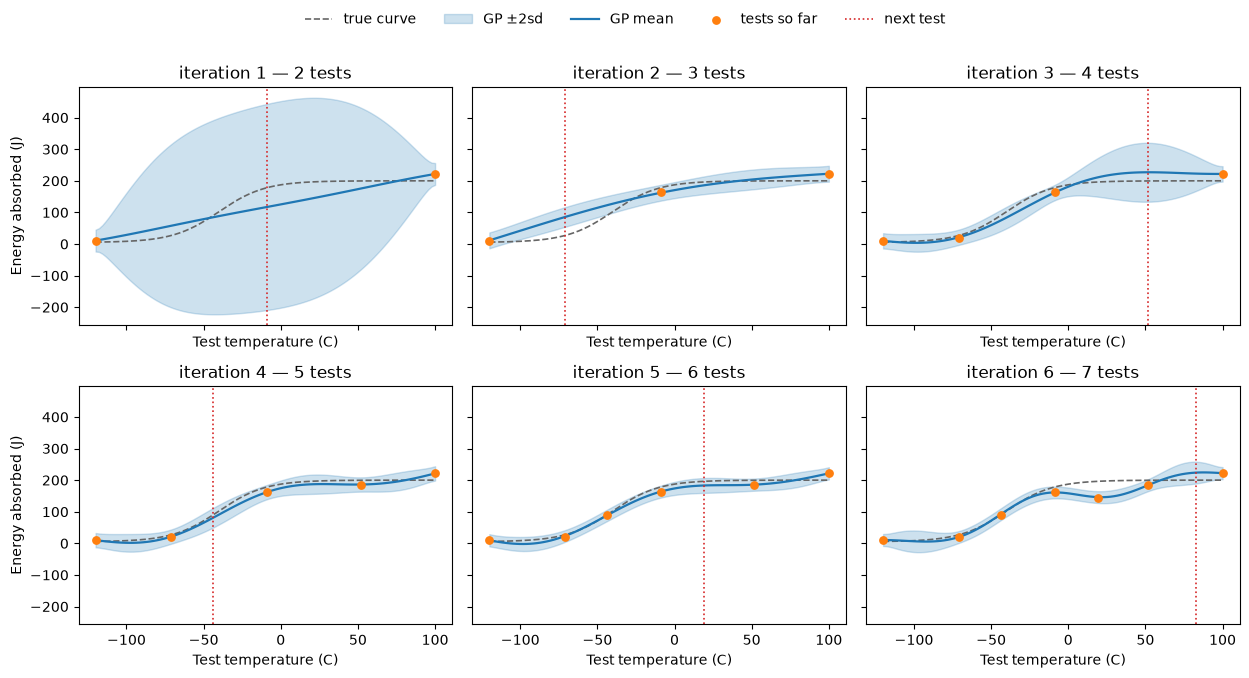

In [17]:
grid = np.linspace(*BOUNDS, 400)
truth = simulator.true_curve(grid)

columns = 3
rows = int(np.ceil(len(history) / columns))
fig, axes = plt.subplots(
    rows, columns, figsize=(4.2 * columns, 3.4 * rows), sharex=True, sharey=True
)
axes = np.atleast_1d(axes).ravel()

for ax, step in zip(axes, history):
    panel = step["curve"]
    t = panel[TEMPERATURE_COL].to_numpy()
    mean, sd = panel["mean"].to_numpy(), panel["sd"].to_numpy()

    ax.plot(grid, truth, color=COLOURS["truth"], lw=1.2, ls="--", label="true curve")
    ax.fill_between(t, mean - 2 * sd, mean + 2 * sd, alpha=0.22,
                    color=COLOURS["gp"], label="GP ±2sd")
    ax.plot(t, mean, color=COLOURS["gp"], lw=1.6, label="GP mean")
    ax.scatter(
        step["observed"][TEMPERATURE_COL], step["observed"][ENERGY_COL],
        s=28, color=COLOURS["tests"], zorder=3, label="tests so far",
    )
    for temperature in step["picked"]:
        ax.axvline(temperature, color=COLOURS["picked"], lw=1.2, ls=":", label="next test")

    # The count goes in the title: a shared legend can only carry one label,
    # so putting it there would show every panel the last panel's count.
    ax.set_title(f"iteration {step['iteration']} — {step['n_tests']} tests")

for ax in axes[len(history):]:
    ax.set_visible(False)
for ax in axes[:len(history)]:
    ax.set_xlabel(TEMPERATURE_COL)
for ax in axes[::columns]:
    ax.set_ylabel(ENERGY_COL)

handles, labels = axes[0].get_legend_handles_labels()
seen = dict(zip(labels, handles))
fig.legend(seen.values(), seen.keys(), loc="upper center", ncol=5, frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

### Where the acquisition chose to test

Every chosen temperature, in order. An uncertainty-reduction acquisition should
cluster these around the transition rather than spreading them evenly — the
shelves are already pinned by the initial design, so there is little left to
learn out there.

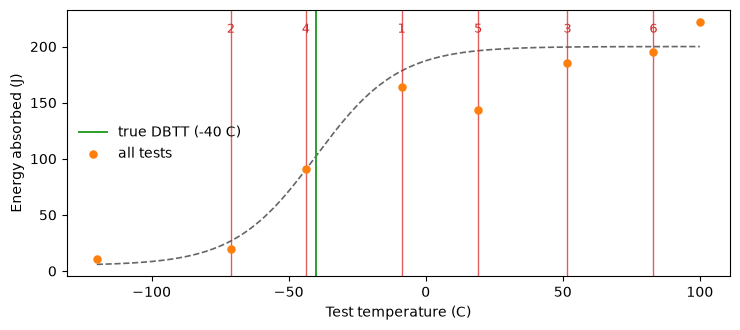

In [18]:
chosen = [(step["iteration"], t) for step in history for t in step["picked"]]

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(grid, truth, color=COLOURS["truth"], lw=1.2, ls="--")
ax.axvline(simulator.dbtt, color=COLOURS["true_dbtt"], lw=1.4, label=f"true DBTT ({simulator.dbtt:g} C)")
for iteration, temperature in chosen:
    ax.axvline(temperature, color=COLOURS["picked"], lw=1.0, alpha=0.75)
    ax.annotate(
        str(iteration), (temperature, ax.get_ylim()[1]),
        ha="center", va="bottom", fontsize=9, color=COLOURS["picked"],
    )
ax.scatter(
    campaign[TEMPERATURE_COL], campaign[ENERGY_COL],
    s=26, color=COLOURS["tests"], zorder=3, label="all tests",
)
ax.set_xlabel(TEMPERATURE_COL)
ax.set_ylabel(ENERGY_COL)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### The posterior as a saved dataset

`Temp to Energy - GP plot` returns a payload that lives only as long as the
job. **Predict slice** runs the same prediction but *saves* the posterior mean
and uncertainty as project datasets, so they persist, can be opened in the GUI,
and can be downloaded and compared later.

Mean and uncertainty are separate resources, because `PredictModel` emits them
as separate handles and no node here joins two datasets. `saved_prediction()`
downloads both and puts them beside the grid, which comes back inline with the
job.

In [19]:
run_saved(client, project_id, saved_ids["Train model"])  # train on the final campaign

posterior_curve = saved_prediction(
    client, project_id,
    run_saved(client, project_id, saved_ids["Predict slice"]),
)
print(f"saved as {MEAN_NAME!r} and {UNCERTAINTY_NAME!r} in the project")
posterior_curve.head()

saved as 'dbtt_gp_mean' and 'dbtt_gp_sd' in the project


,Test temperature (C),mean,sd
0,-120.0,10.537901,9.612855
1,-117.8,11.128079,10.176858
2,-115.6,11.560016,11.714520
3,-113.4,11.839017,13.667425
4,-111.2,11.973440,15.666788


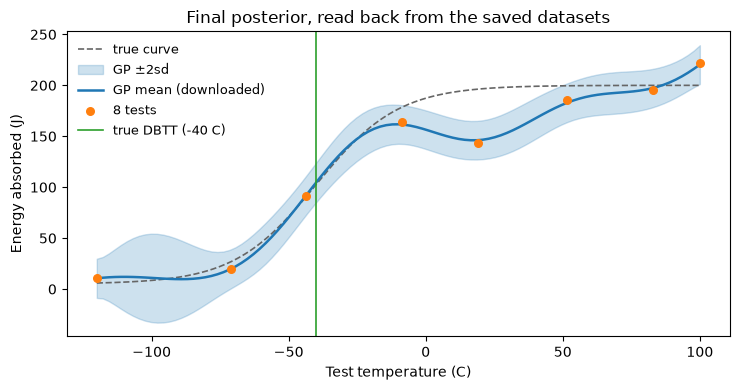

In [20]:
t_curve = posterior_curve[TEMPERATURE_COL].to_numpy()
mean_curve = posterior_curve["mean"].to_numpy()
sd_curve = posterior_curve["sd"].to_numpy()

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(grid, truth, color="0.4", lw=1.2, ls="--", label="true curve")
ax.fill_between(
    t_curve, mean_curve - 2 * sd_curve, mean_curve + 2 * sd_curve,
    alpha=0.22, color="C0", label="GP ±2sd",
)
ax.plot(t_curve, mean_curve, color="C0", lw=1.8, label="GP mean (downloaded)")
ax.scatter(
    campaign[TEMPERATURE_COL], campaign[ENERGY_COL],
    s=30, color="C1", zorder=3, label=f"{len(campaign)} tests",
)
ax.axvline(simulator.dbtt, color="C2", lw=1.2, label=f"true DBTT ({simulator.dbtt:g} C)")
ax.set_xlabel(TEMPERATURE_COL)
ax.set_ylabel(ENERGY_COL)
ax.set_title("Final posterior, read back from the saved datasets")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

### Validation

The validation workflow scores the final model and produces a parity plot. It
is pointed at the campaign itself here, so these are **training** scores — swap
`dataset_id` for a held-out resource to get an honest generalisation estimate.

In [21]:
scores = outputs(run_saved(client, project_id, saved_ids["Validate energy model"]))
as_frame(scores["Score_scores"])

,metric_name,score
0,MSE,3.091706
1,RMSE,1.758325
2,R2,0.999450


---
<a id="section-3"></a>
## 3. The DBTT, with its uncertainty

The GP is a good *interpolator*, but it has no notion of a transition
temperature: reading one off a posterior mean gives a number with no
uncertainty attached. This section answers the question the campaign is
actually for, from the model section 2 produced.

Take the GP posterior that section 2 saved and draw the mid-shelf energy
$(LS + US)/2$ across it as a horizontal line, with the shelves taken as the
extremes the slice reaches. Where the **posterior mean** meets that line is
the DBTT. Where the **credible band** still contains it — from where the
band's upper edge rises through the level to where its lower edge does — is
the interval: every temperature at which the curve could still be at
mid-shelf.

There is no new Engine work here. `posterior_curve` is the slice the
**Predict slice** workflow already saved to the project and we downloaded
above.

> **What this does and does not assume.** Inverting the band needs no
> linearisation and never divides by the transition gradient, so a shallow
> transition widens the interval rather than being flattered by it, and the
> result is asymmetric in general. But the band is *pointwise*, so the
> coverage is nominal only approximately; and it is *predictive*, carrying the
> material's test-to-test scatter, so the interval answers "where could a
> fresh specimen read mid-shelf?" — wider than "where does the underlying
> curve cross mid-shelf?". The notes at the end return to both.

In [22]:
#@title Reading the DBTT off a fitted curve { display-mode: "form" }
# Covers
#   dbtt_from_curve()    the DBTT read off a fitted model's posterior curve.
#                        The point estimate is where the posterior *mean*
#                        crosses the mid-shelf energy; the interval is the
#                        stretch of temperature over which the credible *band*
#                        still straddles that energy.
#   CurveDBTT            what it returns - the crossing, the interval around
#                        it, the mid-shelf level and the gradient there.
#
# The posterior curve itself comes from the Engine (section 2). Everything
# here is arithmetic on that curve, so the cell needs nothing but numpy.


def _erfinv(mass: float) -> float:
    """Inverse error function at ``mass``, by bisection on ``math.erf``.

    Only ever called with one scalar, so a short bisection is cheaper to read
    than the rational approximation and avoids taking scipy back as a
    dependency for a single number.
    """
    import math

    lo, hi = 0.0, 6.0
    for _ in range(200):
        mid = 0.5 * (lo + hi)
        if math.erf(mid) < mass:
            lo = mid
        else:
            hi = mid
    return 0.5 * (lo + hi)

def _crossings(t: np.ndarray, y: np.ndarray, level: float):
    """Every (temperature, slope) where ``y`` crosses ``level``, interpolated."""
    above = y >= level
    out = []
    for i in np.flatnonzero(np.diff(above.astype(int)) != 0):
        t0, t1, y0, y1 = t[i], t[i + 1], y[i], y[i + 1]
        slope = (y1 - y0) / (t1 - t0)
        out.append((t0 + (level - y0) / slope if slope != 0 else t0, slope))
    return out


@dataclass
class CurveDBTT:
    """The DBTT read off a fitted model's posterior curve."""

    dbtt: float                 # where the posterior mean crosses mid-shelf [C]
    low: Optional[float]        # interval start; None if it runs off the slice
    high: Optional[float]       # interval end;   None if it runs off the slice
    has_band: bool              # False when no `sd` was given: no interval at all
    credible_mass: float        # the mass of the band that was inverted
    level: float                # the mid-shelf energy being crossed [J]
    gradient: float             # curve slope there [J/C]; reported, not used
    lower_shelf: float
    upper_shelf: float
    n_crossings: int            # >1 means the mean is not monotonic

    @property
    def width(self) -> Optional[float]:
        """Interval width [C], or None if either end is unbounded."""
        if self.low is None or self.high is None:
            return None
        return self.high - self.low

    def __repr__(self) -> str:
        if not self.has_band:
            return f"CurveDBTT(dbtt={self.dbtt:.2f}, no band given)"
        fmt = lambda v: "unbounded" if v is None else f"{v:.2f}"
        return (f"CurveDBTT(dbtt={self.dbtt:.2f}, "
                f"{self.credible_mass:.0%} interval "
                f"[{fmt(self.low)}, {fmt(self.high)}])")


def dbtt_from_curve(temperature, mean, sd=None, credible_mass: float = 0.95) -> CurveDBTT:
    """Read the DBTT off a fitted model's posterior, with its uncertainty.

    This works on a model's own posterior curve - the mean and standard
    deviation a GP predicts across a temperature slice - rather than on the
    measurements. The DBTT is where the mean crosses the mid-shelf energy,
    ``(LS + US) / 2``, with the shelves taken as the curve's extremes.

    The interval is the band inverted. Draw the mid-shelf energy as a
    horizontal line across the credible band; the temperatures at which the
    band still contains that line are the temperatures at which the curve
    could still be at mid-shelf. Equivalently, the ends are where the band's
    two edges cross the level, and they are found the same way the crossing
    itself is - no linearisation, and no dividing by the gradient, so a
    shallow transition widens the interval instead of being flattered by it.
    The interval is asymmetric in general, which is the point.

    Two caveats travel with it. The band is *pointwise*, so inverting it gives
    approximately rather than exactly the nominal coverage. And the band is
    *predictive* - it carries the material's test-to-test scatter - so the
    interval answers "where could a fresh specimen read mid-shelf?", which is
    wider than "where does the underlying curve cross mid-shelf?".

    ``low`` or ``high`` come back as None when the band still straddles the
    level at the end of the slice: the data does not bound the DBTT on that
    side, and a wider ``BOUNDS`` is the fix.
    """
    t = np.asarray(temperature, dtype=float).reshape(-1)
    y = np.asarray(mean, dtype=float).reshape(-1)
    if t.size != y.size:
        raise ValueError(f"temperature and mean differ in length: {t.size} vs {y.size}")
    if t.size < 3:
        raise ValueError("need at least three points to locate a crossing")
    if not 0.0 < credible_mass < 1.0:
        raise ValueError(f"credible_mass must lie in (0, 1), got {credible_mass}")

    s = None
    if sd is not None:
        s = np.asarray(sd, dtype=float).reshape(-1)
        # Validate before reordering: indexing a short `sd` with the full
        # ordering raises IndexError rather than saying what is wrong.
        if s.size != t.size:
            raise ValueError(f"sd differs in length: {s.size} vs {t.size}")

    order = np.argsort(t)
    t, y = t[order], y[order]
    if s is not None:
        s = s[order]

    lower_shelf, upper_shelf = float(y.min()), float(y.max())
    level = 0.5 * (lower_shelf + upper_shelf)

    found = _crossings(t, y, level)
    if not found:
        raise ValueError(
            "the curve never crosses its own mid-shelf energy; it is probably "
            "not a transition over this range"
        )
    # The steepest crossing is the transition; any others are GP wiggle.
    dbtt, gradient = max(found, key=lambda c: abs(c[1]))

    low = high = None
    if s is not None:
        # The two-sided z for this mass, without pulling scipy in for one number.
        z = float(np.sqrt(2.0) * _erfinv(credible_mass))
        hi_edge, lo_edge = y + z * s, y - z * s

        # Where the band straddles the level at all. The mean crosses inside
        # this set by construction, so the run containing the crossing is the
        # interval; other runs belong to other crossings.
        inside = (lo_edge <= level) & (level <= hi_edge)
        here = int(np.argmin(np.abs(t - dbtt)))
        if not inside[here]:                      # only reachable on a tie at
            here = int(np.flatnonzero(inside)[0]) # the very edge of a cell

        start = here
        while start > 0 and inside[start - 1]:
            start -= 1
        stop = here
        while stop < t.size - 1 and inside[stop + 1]:
            stop += 1

        # Refine each end onto whichever edge actually closes the band there.
        # Which one that is depends on the direction of the transition: on a
        # rising curve the band opens as its upper edge reaches the level and
        # shuts as its lower edge passes it, and on a falling curve the roles
        # swap. Picking by `inside` rather than by assumption handles both.
        def close(outside: int, a: int, b: int) -> float:
            edge = hi_edge if hi_edge[outside] < level else lo_edge
            t0, t1, e0, e1 = t[a], t[b], edge[a], edge[b]
            return float(t0 + (level - e0) * (t1 - t0) / (e1 - e0)) if e1 != e0 else float(t0)

        if start > 0:
            low = close(start - 1, start - 1, start)
        if stop < t.size - 1:
            high = close(stop + 1, stop, stop + 1)

    return CurveDBTT(
        dbtt=float(dbtt), low=low, high=high, has_band=s is not None,
        credible_mass=float(credible_mass),
        level=level, gradient=float(gradient),
        lower_shelf=lower_shelf, upper_shelf=upper_shelf, n_crossings=len(found),
    )

In [23]:
read = dbtt_from_curve(
    posterior_curve[TEMPERATURE_COL], posterior_curve["mean"], posterior_curve["sd"]
)
print(read)
print(f"  mid-shelf level: {read.level:.1f} J   gradient there: {read.gradient:.3f} J/C")
print(f"  shelves read off the slice: LS = {read.lower_shelf:.1f} J, US = {read.upper_shelf:.1f} J")
print(f"  interval width: {read.width:.2f} C"
      if read.width is not None else
      "  interval unbounded on one side - widen BOUNDS")
print(f"  mean crossings found: {read.n_crossings}")

CurveDBTT(dbtt=-36.87, 95% interval [-42.40, -29.89])
  mid-shelf level: 115.0 J   gradient there: 3.310 J/C
  shelves read off the slice: LS = 9.7 J, US = 220.3 J
  interval width: 12.51 C
  mean crossings found: 1


### How it compares to the truth

The simulator knows the answer, so the estimate can be scored directly — a
luxury no real campaign has. What matters is not whether the point estimate
lands close, but whether the interval is *honest*: a 95% interval that misses
the truth is a worse result than a wider one that contains it.

In [24]:
low, high = read.low, read.high
contains = (low is not None and high is not None
            and low <= simulator.dbtt <= high)

# An end is None when the band never closed inside BOUNDS. Say so rather than
# formatting it as a number.
show = lambda v: "unbounded" if v is None else f"{v:.2f}"
print(f"{read.credible_mass:.0%} interval [{show(low)}, {show(high)}] "
      f"{'contains' if contains else 'does NOT contain'} the true DBTT "
      f"({simulator.dbtt:g} C)")
if low is not None and high is not None:
    print(f"  the estimate sits {read.dbtt - low:.2f} C above the lower end and "
          f"{high - read.dbtt:.2f} C below the upper one - the interval is "
          "asymmetric, which a +/- number cannot say")

pd.DataFrame([
    {"quantity": "GP crossing", "DBTT (C)": read.dbtt,
     "low": np.nan if low is None else low,
     "high": np.nan if high is None else high,
     "width (C)": np.nan if read.width is None else read.width},
    {"quantity": "truth", "DBTT (C)": simulator.dbtt,
     "low": np.nan, "high": np.nan, "width (C)": np.nan},
]).round(2)


95% interval [-42.40, -29.89] contains the true DBTT (-40 C)
  the estimate sits 5.53 C above the lower end and 6.98 C below the upper one - the interval is asymmetric, which a +/- number cannot say


,quantity,DBTT (C),low,high,width (C)
0,GP crossing,-36.87,-42.4,-29.89,12.51
1,truth,-40.00,NaN,NaN,NaN


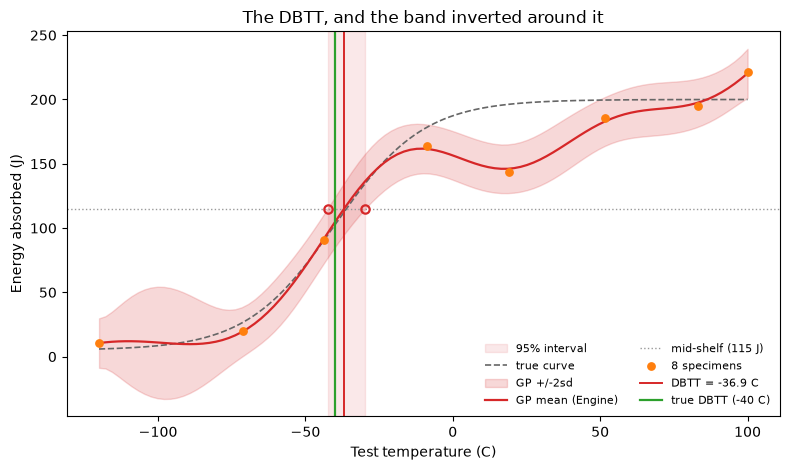

In [25]:
t = campaign[TEMPERATURE_COL].to_numpy()
y = campaign[ENERGY_COL].to_numpy()

fig, ax = plt.subplots(figsize=(8, 4.8))

# An unbounded end is drawn out to the edge of the tested range, where the
# band stopped closing - not as a bound the campaign actually established.
span_low = BOUNDS[0] if low is None else low
span_high = BOUNDS[1] if high is None else high
ax.axvspan(span_low, span_high, color=COLOURS["dbtt"], alpha=0.10,
           label=f"{read.credible_mass:.0%} interval")
ax.plot(grid, truth, color=COLOURS["truth"], lw=1.2, ls="--", label="true curve")
ax.fill_between(
    t_curve, mean_curve - 2 * sd_curve, mean_curve + 2 * sd_curve,
    color=COLOURS["posterior"], alpha=0.18, label="GP +/-2sd",
)
ax.plot(t_curve, mean_curve, color=COLOURS["posterior"], lw=1.6, label="GP mean (Engine)")
ax.axhline(read.level, color="0.6", lw=1.0, ls=":",
           label=f"mid-shelf ({read.level:.0f} J)")

# The construction, drawn: the level meets the band here and leaves it there.
for edge in (low, high):
    if edge is not None:
        ax.plot([edge], [read.level], marker="o", ms=6, mfc="none",
                mec=COLOURS["dbtt"], mew=1.6, zorder=4)

ax.scatter(t, y, s=28, color=COLOURS["tests"], zorder=3, label=f"{len(t)} specimens")
ax.axvline(read.dbtt, color=COLOURS["dbtt"], lw=1.4, label=f"DBTT = {read.dbtt:.1f} C")
ax.axvline(simulator.dbtt, color=COLOURS["true_dbtt"], lw=1.6,
           label=f"true DBTT ({simulator.dbtt:g} C)")

ax.set_xlabel(TEMPERATURE_COL)
ax.set_ylabel(ENERGY_COL)
ax.set_title("The DBTT, and the band inverted around it")
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

### The estimate against the specimen count

The GP posterior was saved at every iteration, so the same construction can be
run on each one — no extra Engine work, just arithmetic on curves already in
`history`. The result is the campaign's own learning curve: the estimate, and
the interval around it, against the number of specimens spent on it.

Inverting the band makes this trace better behaved than dividing by a gradient
did, because the interval no longer depends on a slope that moves with every
refit. It still need not shrink monotonically — each iteration refits the GP on
a dataset that has changed, and a specimen that widens the band locally widens
the interval with it — but the swings are driven by the band itself rather than
by a linearisation on top of it.

Watch the ends separately from the width. An interval that has stopped moving
is not the same as one that has stopped being wide, and for a campaign this
short neither is guaranteed.

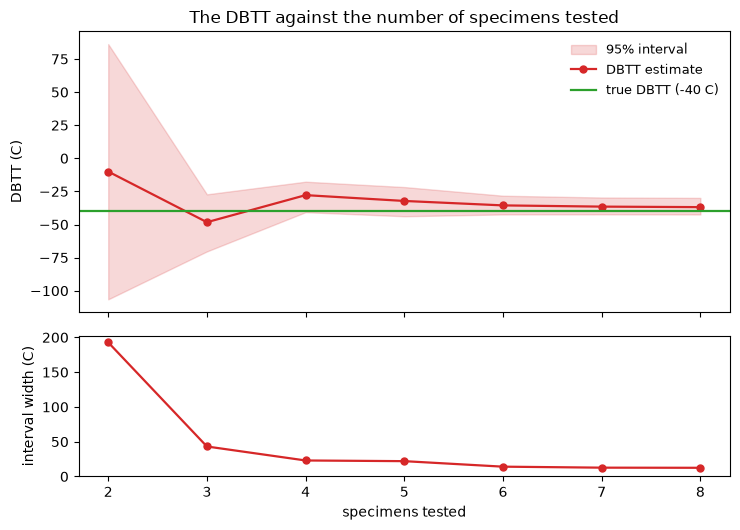

,n_tests,dbtt,low,high,width
0,2,-10.00,-106.51,86.26,192.77
1,3,-48.26,-70.33,-27.20,43.13
2,4,-27.81,-40.68,-17.66,23.03
3,5,-32.21,-43.76,-21.71,22.05
4,6,-35.56,-42.38,-28.25,14.13
5,7,-36.48,-42.31,-29.61,12.70
6,8,-36.87,-42.40,-29.89,12.51


In [26]:
track = []
for step in history:
    panel = step["curve"]
    try:
        step_read = dbtt_from_curve(panel[TEMPERATURE_COL], panel["mean"], panel["sd"])
    except ValueError:
        continue  # an early GP need not cross its own mid-shelf energy at all
    track.append({
        "n_tests": step["n_tests"], "dbtt": step_read.dbtt,
        # None means the band never closed within BOUNDS; NaN leaves a visible
        # gap in the figure rather than inventing a bound that is not there.
        "low": np.nan if step_read.low is None else step_read.low,
        "high": np.nan if step_read.high is None else step_read.high,
    })

# `history` records each iteration *before* its pick is tested, so the final
# campaign is only represented by the read made at the top of section 3.
track.append({"n_tests": len(campaign), "dbtt": read.dbtt,
              "low": np.nan if low is None else low,
              "high": np.nan if high is None else high})
track = pd.DataFrame(track)
track["width"] = track["high"] - track["low"]

fig, (top, bottom) = plt.subplots(
    2, 1, figsize=(7.5, 5.4), sharex=True, gridspec_kw={"height_ratios": [2, 1]}
)

top.fill_between(track["n_tests"], track["low"], track["high"],
                 color=COLOURS["dbtt"], alpha=0.18,
                 label=f"{read.credible_mass:.0%} interval")
top.plot(track["n_tests"], track["dbtt"], "o-", color=COLOURS["dbtt"],
         lw=1.6, ms=5, label="DBTT estimate")
top.axhline(simulator.dbtt, color=COLOURS["true_dbtt"], lw=1.6,
            label=f"true DBTT ({simulator.dbtt:g} C)")
top.set_ylabel("DBTT (C)")
top.legend(frameon=False, fontsize=9)
top.set_title("The DBTT against the number of specimens tested")

bottom.plot(track["n_tests"], track["width"], "o-", color=COLOURS["dbtt"], lw=1.6, ms=5)
bottom.set_xlabel("specimens tested")
bottom.set_ylabel("interval width (C)")
bottom.set_ylim(bottom=0)

fig.tight_layout()
plt.show()

track.round(2)

---
<a id="section-4"></a>
## 4. Was the active learning worth it?

Everything so far assumed that choosing *where* to test beats deciding in
advance. This section tests that, by running three fixed designs through
exactly the same machinery — upload, train on the Engine, predict the slice,
invert the band — and putting their answers beside the active-learning one.

| Design | Specimens | The idea |
| --- | --- | --- |
| Evenly spaced, 10 | 10 | The obvious thing to do with a small budget |
| Evenly spaced, 30 | 30 | The same idea with three times the specimens |
| 10 temperatures, 3 repeats | 30 | The same budget as above, spent on replication instead of resolution |

The third is the interesting one. A test house often prefers repeats: they
measure the scatter directly and are easier to schedule. The question is
whether thirty specimens at ten temperatures tell you more about the
*transition* than thirty specimens at thirty temperatures.

> **What this comparison is and is not.** Every design is one realisation,
> drawn from the same simulator with the same noise settings. Differences of a
> degree or two are noise, not evidence, and a fair benchmark would repeat each
> design over many seeds and compare the *distribution* of intervals. What a
> single run can show is the shape of the thing: whether a design brackets the
> truth at all, and roughly what it costs to do so.

In [27]:
BASELINES = [
    ("Evenly spaced, 10", np.linspace(*BOUNDS, 10)),
    ("Evenly spaced, 30", np.linspace(*BOUNDS, 30)),
    ("10 temperatures, 3 repeats", np.repeat(np.linspace(*BOUNDS, 10), 3)),
]


def run_fixed_design(label: str, temperatures) -> dict:
    """Take one fixed design all the way to a DBTT, through the Engine.

    The same path section 2 took, minus the loop: upload the campaign, train a
    GP on it, predict across the slice, and invert the band. Each design gets
    its own resources so nothing here disturbs the active-learning ones, and
    re-running the notebook versions them in place rather than piling up.
    """
    slug = label.lower().replace(",", "").replace(" ", "_")
    design = simulator.run(list(map(float, temperatures)), start_index=1)

    dataset = upload_dataset(client, project_id, design, f"dbtt_baseline_{slug}")
    training = build_training_workflow(
        client, project_id, dataset, f"dbtt_gp_{slug}",
        kernel=KERNEL, model_type=MODEL_TYPE, warp_inputs=WARP_INPUTS, seed=MODEL_SEED,
    )
    run_saved(client, project_id,
              save_workflow(client, project_id, training, f"Baseline train - {label}"))
    model = resource_id(client, project_id, f"dbtt_gp_{slug}", "model")

    prediction = build_prediction_workflow(
        client, project_id, model, BOUNDS,
        f"dbtt_mean_{slug}", f"dbtt_sd_{slug}",
    )
    response = run_saved(client, project_id,
                         save_workflow(client, project_id, prediction,
                                       f"Baseline predict - {label}"))
    curve = saved_prediction(client, project_id, response)

    return {"label": label, "design": design, "curve": curve,
            "read": dbtt_from_curve(curve[TEMPERATURE_COL], curve["mean"], curve["sd"])}


results = []
for label, temperatures in BASELINES:
    print(f"{label} ({len(temperatures)} specimens) ...", end=" ", flush=True)
    results.append(run_fixed_design(label, temperatures))
    print(results[-1]["read"])

Evenly spaced, 10 (10 specimens) ... 

CurveDBTT(dbtt=-38.83, 95% interval [-51.29, -26.43])
Evenly spaced, 30 (30 specimens) ... 

CurveDBTT(dbtt=-35.87, 95% interval [-48.88, -22.68])
10 temperatures, 3 repeats (30 specimens) ... 

CurveDBTT(dbtt=-41.95, 95% interval [-57.56, -25.81])


### Side by side

`width` is what the campaign actually bought: how tightly the data pins the
DBTT down. `contains` is whether it was honest about it — an interval that
misses the truth is a worse outcome than a wide one that does not.

In [28]:
def summarise(label: str, n: int, at) -> dict:
    inside = (at.low is not None and at.high is not None
              and at.low <= simulator.dbtt <= at.high)
    return {"design": label, "specimens": n, "DBTT (C)": at.dbtt,
            "low": np.nan if at.low is None else at.low,
            "high": np.nan if at.high is None else at.high,
            "width (C)": np.nan if at.width is None else at.width,
            "error (C)": at.dbtt - simulator.dbtt,
            "contains truth": inside}


comparison = pd.DataFrame(
    [summarise(f"Active learning ({ACQUISITION})", len(campaign), read)]
    + [summarise(r["label"], len(r["design"]), r["read"]) for r in results]
)
comparison.round(2)

,design,specimens,DBTT (C),low,high,width (C),error (C),contains truth
0,Active learning (qNIPV),8,-36.87,-42.40,-29.89,12.51,3.13,True
1,"Evenly spaced, 10",10,-38.83,-51.29,-26.43,24.85,1.17,True
2,"Evenly spaced, 30",30,-35.87,-48.88,-22.68,26.19,4.13,True
3,"10 temperatures, 3 repeats",30,-41.95,-57.56,-25.81,31.75,-1.95,True


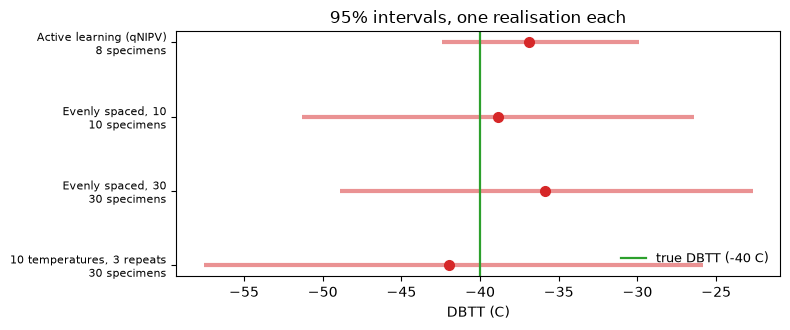

In [29]:
fig, ax = plt.subplots(figsize=(8, 3.4))

rows = comparison.iloc[::-1].reset_index(drop=True)   # first design at the top
for y, row in rows.iterrows():
    colour = COLOURS["dbtt"] if row["contains truth"] else "firebrick"
    ax.plot([row["low"], row["high"]], [y, y], lw=3, color=colour, alpha=0.5,
            solid_capstyle="butt")
    ax.plot([row["DBTT (C)"]], [y], "o", ms=7, color=colour)

ax.axvline(simulator.dbtt, color=COLOURS["true_dbtt"], lw=1.6,
           label=f"true DBTT ({simulator.dbtt:g} C)")
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([f"{r['design']}\n{r['specimens']} specimens" for _, r in rows.iterrows()],
                   fontsize=8)
ax.set_xlabel("DBTT (C)")
ax.set_title(f"{read.credible_mass:.0%} intervals, one realisation each")
ax.legend(frameon=False, fontsize=9, loc="lower right")
fig.tight_layout()
plt.show()

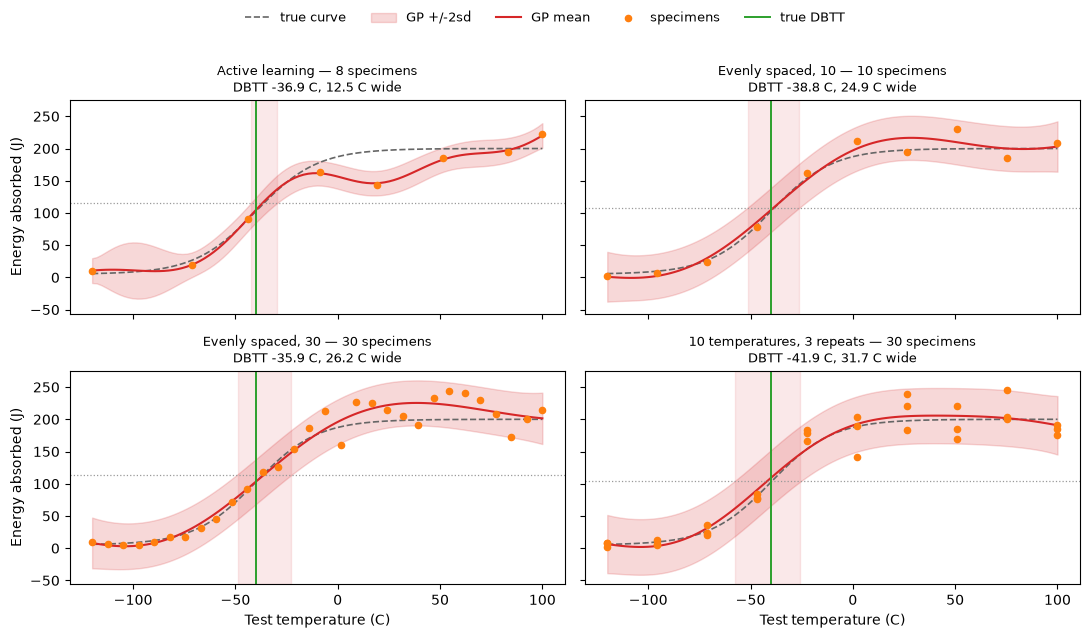

In [30]:
panels = [("Active learning", campaign, posterior_curve, read)] + [
    (r["label"], r["design"], r["curve"], r["read"]) for r in results
]

fig, axes = plt.subplots(2, 2, figsize=(11, 6.4), sharex=True, sharey=True)
for ax, (label, design, curve, at) in zip(axes.ravel(), panels):
    temperature = curve[TEMPERATURE_COL].to_numpy()
    mean, sd = curve["mean"].to_numpy(), curve["sd"].to_numpy()

    if at.low is not None and at.high is not None:
        ax.axvspan(at.low, at.high, color=COLOURS["dbtt"], alpha=0.10)
    ax.plot(grid, truth, color=COLOURS["truth"], lw=1.2, ls="--", label="true curve")
    ax.fill_between(temperature, mean - 2 * sd, mean + 2 * sd,
                    color=COLOURS["posterior"], alpha=0.18, label="GP +/-2sd")
    ax.plot(temperature, mean, color=COLOURS["posterior"], lw=1.5, label="GP mean")
    ax.axhline(at.level, color="0.6", lw=0.9, ls=":")
    ax.scatter(design[TEMPERATURE_COL], design[ENERGY_COL], s=20,
               color=COLOURS["tests"], zorder=3, label="specimens")
    ax.axvline(simulator.dbtt, color=COLOURS["true_dbtt"], lw=1.4, label="true DBTT")

    width = "unbounded" if at.width is None else f"{at.width:.1f} C wide"
    ax.set_title(f"{label} — {len(design)} specimens\nDBTT {at.dbtt:.1f} C, {width}",
                 fontsize=9)

for ax in axes[-1]:
    ax.set_xlabel(TEMPERATURE_COL)
for ax in axes[:, 0]:
    ax.set_ylabel(ENERGY_COL)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(dict(zip(labels, handles)).values(), dict(zip(labels, handles)).keys(),
           loc="upper center", ncol=5, frameon=False, fontsize=9)
fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

### What that says

All four designs bracket the truth, so none of them is *wrong*. What separates
them is the width, and the width does not fall with the specimen count:
thirty evenly spaced specimens gave a slightly **wider** interval than ten, and
thirty spent on repeats gave the widest of the lot. Eight, chosen by the
acquisition, gave much the narrowest.

That is not a paradox, and it is worth being precise about why, because it is a
property of the estimator as much as of the designs. The interval is the band
inverted, so its width is roughly

$$\text{width} \;\approx\; \frac{2 z \cdot \mathrm{sd}(T^*)}{\left|\mathrm{d}Y/\mathrm{d}T\right|(T^*)}$$

and the band is *predictive*: it carries the material's test-to-test scatter,
so $\mathrm{sd}$ bottoms out at $\sigma(T)$ however many specimens are added.
More data barely moves the numerator. That leaves the denominator — the
gradient where the curve crosses mid-shelf — doing nearly all the work, and the
gradient is resolved by putting specimens *in the transition*, not by spreading
them evenly across a range that is mostly flat shelf.

Hence the ordering. Evenly spaced designs spend most of their budget on the
shelves, where the curve has nothing left to say, and tripling that budget
triples the shelf coverage without sharpening the transition. The repeats
design is worst because it is coarsest where it matters: thirty specimens at
ten temperatures resolve the transition's *shape* less well than thirty at
thirty, whatever they buy in knowledge of the scatter.

Two honest qualifications. **The point estimates tell a different story from
the widths** — evenly spaced with ten specimens landed closest to the truth
here, at 1.17 C, better than active learning's 3.13 C. With one realisation
each that is luck, not a finding, and it is exactly why the width matters more
than the error: the width is what you would have to report, having no truth to
check against. And **a narrow interval is a claim, not a guarantee** — the
active-learning interval is the one with least room to be wrong, which makes it
the one to distrust first if the transition turns out not to be where the
campaign concentrated its specimens.

---
## Notes

- **The interval is the deliverable, not the point estimate.** A campaign of
  this size pins the DBTT down to a few degrees; quoting a single number hides
  that.
- **The band is pointwise, so the coverage is approximate.** The interval is
  the set of temperatures at which a pointwise credible band still contains
  the mid-shelf energy. Inverting a pointwise band does not give exactly the
  nominal mass — a simultaneous band would, and would be wider. What it does
  avoid is the delta method's linearisation: nothing here is divided by the
  transition gradient, so a shallow or poorly resolved transition widens the
  interval instead of being flattered by it, and the result is asymmetric in
  general.
- **The band is predictive, so the interval is conservative.** It carries the
  material's test-to-test scatter, which means it answers "where could a fresh
  specimen read mid-shelf?" rather than "where does the underlying curve cross
  mid-shelf?". The second is the narrower question and the one you probably
  want; separating them needs the epistemic part of the variance on its own,
  which the Engine does not return. Read the interval as the conservative of
  the two.
- **An end can be unbounded.** If the band still straddles the mid-shelf level
  at the edge of the slice, that end comes back as `None`: the campaign does
  not bound the DBTT on that side. Widen `BOUNDS` rather than reporting a
  number the data does not support.
- **The GP has no notion of a transition.** The crossing is read off a curve
  fitted for interpolation, so the shelves are whatever extremes the slice
  happens to reach. A slice that stops short of either shelf moves the
  mid-shelf level, and the answer with it — keep `BOUNDS` wide enough that the
  curve is flat at both ends.
- **A model-free route exists and is not in this notebook.** Fitting the AHT
  form to the measurements directly makes the problem linear in the shelves,
  so they and the noise precision integrate out in closed form, and sweeping
  the evidence over a `(DBTT, C)` grid gives `p(DBTT | data)` itself — an
  asymmetric density rather than a ± number. It is a different estimator of
  the same quantity, with a spread that is not comparable like-for-like to
  this one. It was removed when this section was cut back to the GP route and
  is recoverable from git history.
- **Two things about reading Engine results.** Only some node outputs come
  back as *values* — `UncertaintyPlot` returns the posterior inline, while
  `PredictModel`'s and `Recommend`'s own handles return S3 references. And
  creating a resource is a different call from versioning one: `upload`
  refuses a name the project already holds, `update` adds a version and keeps
  the id. The saved workflows point at that id, which is why the loop never
  has to edit a graph.
- **The band plateaus, it does not vanish.** It is the predictive standard
  deviation, so it bottoms out at the material's test-to-test scatter however
  many specimens are added.